# Synthetic Data Generation with Diffusion Models — Google Colab Runner

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AleksyPrawilow/synthetic-data/blob/main/colab.ipynb)

> **Zero Local Bloat:** Run all diffusion models, image generation, CNN fine-tuning, and evaluation on a Google Colab cloud GPU. Your local computer stays clean without downloading hundreds of megabytes of datasets or multi-gigabyte model weights.

### ⚡ Hardware Accelerator Requirement
Make sure GPU acceleration is enabled before running:
1. In the top menu, select **Runtime** ➔ **Change runtime type**.
2. Under **Hardware accelerator**, select **T4 GPU** (or L4 / A100).
3. Click **Save**.

## 0. Verify GPU & Environment
Check that a CUDA-capable GPU is allocated and ready.

In [1]:
import sys
import torch

print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Active GPU: {torch.cuda.get_device_name(0)}")
    !nvidia-smi
else:
    print("\n⚠️ WARNING: GPU is NOT active!")
    print("Please go to: Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU -> Save")


Python Version: 3.13.15
PyTorch Version: 2.11.0+cu130
CUDA Available: True
Active GPU: Tesla T4
Fri Oct 23 14:29:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         | 

## 1. Storage & Repository Setup
Select how you want to work:
- **Option A (Ephemeral / Fast):** Clone to `/content/synthetic-data`. Fastest disk I/O, but remember to push to GitHub or download your results at the end of the session.
- **Option B (Persistent):** Mount Google Drive so your runs, checkpoints, and downloaded datasets persist across Colab disconnects.

In [ ]:
# Optional: Mount Google Drive for persistent storage
# Uncomment if you want to store your repository or cache on Google Drive
# from google.colab import drive
# drive.mount('/content/drive')


In [3]:
import os
from pathlib import Path

# Repository to clone
REPO_URL = "https://github.com/AleksyPrawilow/synthetic-data.git"
REPO_DIR = Path("/content/synthetic-data")

if not REPO_DIR.exists():
    print(f"Cloning {REPO_URL}...")
    !git clone {REPO_URL} {REPO_DIR}
else:
    print(f"Repository exists at {REPO_DIR}.")

%cd {REPO_DIR}
print(f"Current directory: {Path.cwd()}")


Cloning https://github.com/AleksyPrawilow/synthetic-data.git...
Cloning into '/content/synthetic-data'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 39 (delta 7), reused 29 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 89.93 KiB | 7.49 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/synthetic-data
Current directory: /content/synthetic-data


## 2. Install Project Dependencies
Install the project in editable mode (`-e .`). This registers the course CLI commands in Colab:
- `synth-data`
- `synth-train`
- `synth-generate`
- `synth-test`

In [4]:
# Install package dependencies and CLI tools into Colab environment
!pip install -e .


Obtaining file:///content/synthetic-data
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.9/5.9 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 94.4 MB/s eta 0:00:00
  Building editable for synthetic-data-course (pyproject.toml) ... done
  Created wheel for synthetic-data-course: filename=synthetic_data_course-0.1.0-py3-none-any.whl size=7373 sha256=472395ba52be5edb50b46eefc8aabc30dde748413d9f5f2f7aae32635996a8bb
  Stored in directory: /tmp/pip-ephem-wheel-cache-2aez7ms9/wheels/ef/39/51/cbb5e5a96b01b94d4e6119abeb070ed21e0595f5d6d8db1a64
Successfully built synthetic-data-course
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalle

## 3. Download Data & Verify Starter Code
Download the Oxford-IIIT Pet dataset (~800 MB) into `data/` and verify the course split, then run tests to verify the installation.

In [1]:
# Download Oxford-IIIT Pet dataset and check split
!synth-data


100% 792M/792M [00:20<00:00, 37.8MB/s]
100% 19.2M/19.2M [00:01<00:00, 14.4MB/s]
breed           train    val   test
Abyssinian         70     20     30
Bengal             70     20     30
Birman             70     20     30
Bombay             70     20     30
Egyptian Mau       15     20     30
Ragdoll            70     20     30
Russian Blue       70     20     30
Siamese            70     20     30

All 905 photos are in place. Egyptian Mau is the minority class.


In [2]:
# Run starter tests
!pytest


============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.7.0
rootdir: /content
plugins: typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.3
collected 16 items                                                             

synthetic-data/tests/test_split.py ....                                  [ 25%]
synthetic-data/tests/test_tools.py ............                          [100%]

============================== 16 passed in 6.34s ==============================


## 4. Colab Visual Inspection & Comparison Helpers
Run this cell to load helper functions for displaying contact sheets, inspecting seed metrics, and comparing runs directly in Colab cells.

In [24]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

def show_contact_sheet(pool_name: str, width: int = 700):
    """Display the contact sheet of a pool inline in the notebook."""
    sheet_path = Path("pools") / pool_name / "contact-sheet.jpg"
    if sheet_path.exists():
        print(f"Contact sheet for: {pool_name}")
        display(Image(filename=str(sheet_path), width=width))
    else:
        print(f"⚠️ Contact sheet not found at: {sheet_path}")

def load_run_results(run_name: str, split: str = "val") -> pd.DataFrame:
    """Load results.json (val) or test-results.json (test) as a DataFrame."""
    fname = "test-results.json" if split == "test" else "results.json"
    path = Path("runs") / run_name / fname
    if not path.exists():
        print(f"Results file not found: {path}")
        return pd.DataFrame()
    with open(path) as f:
        data = json.load(f)
    rows = []
    for s in data.get("seeds", []):
        rows.append({
            "run": run_name,
            "seed": s["seed"],
            "egyptian_mau_recall": s["egyptian_mau_recall"],
            "macro_f1": s["macro_f1"],
            "accuracy": s.get("accuracy", None)
        })
    return pd.DataFrame(rows)

def compare_runs(run_names: list[str], split: str = "val") -> pd.DataFrame:
    """Display side-by-side metric comparison across runs."""
    records = []
    for name in run_names:
        df = load_run_results(name, split=split)
        if not df.empty:
            records.append({
                "Run": name,
                "Split": split,
                "Mau Recall (mean)": f"{df['egyptian_mau_recall'].mean():.4f}",
                "Mau Recall (std)": f"{df['egyptian_mau_recall'].std():.4f}",
                "Macro F1 (mean)": f"{df['macro_f1'].mean():.4f}",
                "Macro F1 (std)": f"{df['macro_f1'].std():.4f}",
                "Seeds": len(df)
            })
    if records:
        summary_df = pd.DataFrame(records)
        display(summary_df)
        return summary_df
    else:
        print("No run data found to compare.")
        return pd.DataFrame()

print("✅ Helper functions loaded: show_contact_sheet(), load_run_results(), compare_runs()")


✅ Helper functions loaded: show_contact_sheet(), load_run_results(), compare_runs()


In [23]:
!git pull

remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 7 (delta 4), reused 7 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 3.64 KiB | 1.21 MiB/s, done.
From https://github.com/AleksyPrawilow/synthetic-data
   7758b8e..e5be2bb  main       -> origin/main
Updating 7758b8e..e5be2bb
Fast-forward
 colab.ipynb              | 114 ++++++++----------------
 src/synthdata/balance.py |  56 ++++++++----
 src/synthdata/reports.py | 226 +++++++++++++++++++++++++++++++++++++++++++++++
 3 files changed, 302 insertions(+), 94 deletions(-)
 create mode 100644 src/synthdata/reports.py


## Meeting 1 — Real-Data Baselines
1. Implement `oversample()` and `augment()` in `src/synthdata/balance.py`.
2. Train the three baseline models (`real`, `oversample`, `augment`).
3. Compare on the validation set, select your candidate, then evaluate on the test photos.

In [17]:
# Check src/synthdata/balance.py
!head -n 45 src/synthdata/balance.py


"""Meeting 1: the two classical ways to add Egyptian Mau training examples.

Both functions are yours to write; `uv run synth-train --method oversample` or
`--method augment` uses them.
"""

import random

from PIL import Image, ImageEnhance, ImageOps

try:
    from torchvision import transforms

    _TORCHVISION_TRANSFORM = transforms.Compose(
        [
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=15),
            transforms.RandomAffine(
                degrees=0,
                translate=(0.04, 0.04),
                scale=(0.95, 1.05),
            ),
            transforms.ColorJitter(
                brightness=0.15,
                contrast=0.15,
                saturation=0.15,
            ),
        ]
    )
except ImportError:
    _TORCHVISION_TRANSFORM = None


def oversample(
    minority_photos: list[str], budget: int, rng: random.Random
) -> list[str]:
    """Choose which Egyptian Mau training photos to repeat.

    Retu

In [18]:
# Train the 3 baselines (5 seeds each)
!synth-train --name m1-real --method real
!synth-train --name m1-oversample --method oversample
!synth-train --name m1-augment --method augment


m1-real: real, efficientnet_b0, 5 seeds, cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 135MB/s] 
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create.

In [28]:
!AUGMENT_LEVEL=strong synth-train --name m1-augment-strong --method augment

m1-augment-strong: augment, efficientnet_b0, 5 seeds, cuda
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_numb

### Val Results by Seed

| Run | Metric | Seed 0 | Seed 1 | Seed 2 | Seed 3 | Seed 4 | Mean ± Std |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| `m1-real` | Mau Recall | 0.450 | 0.500 | 0.450 | 0.450 | 0.600 | 0.490 ± 0.058 |
| `m1-real` | Macro F1 | 0.861 | 0.856 | 0.861 | 0.855 | 0.884 | 0.863 ± 0.011 |
| `m1-oversample` | Mau Recall | 0.600 | 0.600 | 0.650 | 0.650 | 0.750 | 0.650 ± 0.055 |
| `m1-oversample` | Macro F1 | 0.890 | 0.872 | 0.879 | 0.891 | 0.886 | 0.884 ± 0.007 |
| `m1-augment` | Mau Recall | 0.700 | 0.650 | 0.650 | 0.650 | 0.750 | 0.680 ± 0.040 |
| `m1-augment` | Macro F1 | 0.905 | 0.867 | 0.898 | 0.892 | 0.886 | 0.890 ± 0.013 |
| `m1-augment-strong` | Mau Recall | 0.700 | 0.700 | 0.650 | 0.600 | 0.800 | 0.690 ± 0.066 |
| `m1-augment-strong` | Macro F1 | 0.904 | 0.880 | 0.879 | 0.878 | 0.912 | 0.891 ± 0.014 |
✅ Saved plot showing every seed to /content/synthetic-data/evidence/m1_validation_comparison.png


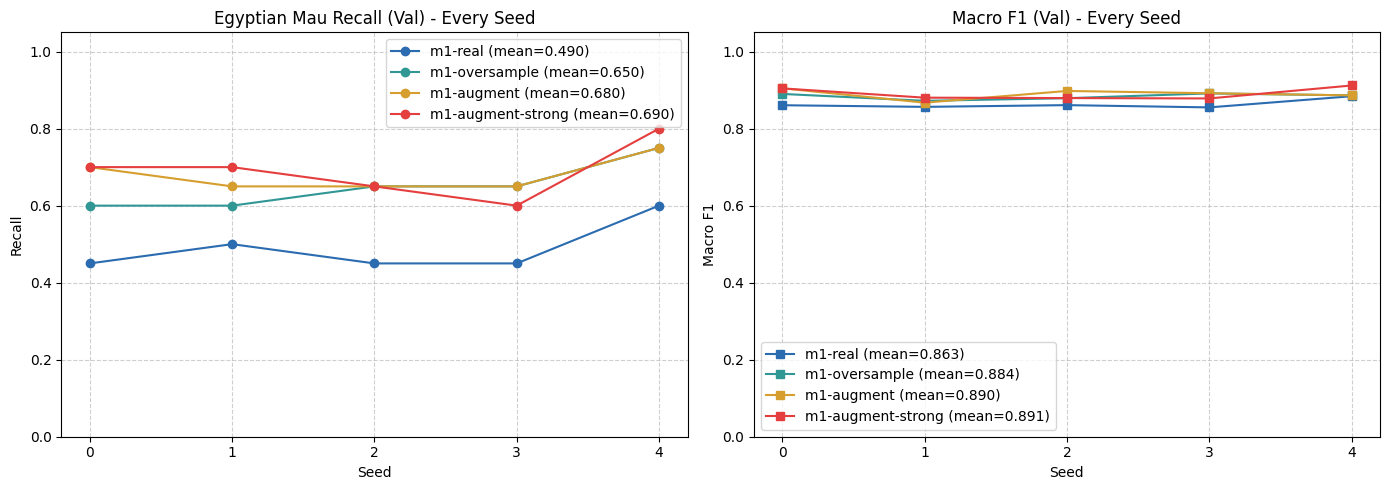

In [29]:
from synthdata.reports import format_seed_table, plot_seeds
m1_runs = ["m1-real", "m1-oversample", "m1-augment", "m1-augment-strong"]
# 1. Prints the Markdown table showing every seed (0 to 4), mean, and std
format_seed_table(m1_runs, split="val")
# 2. Generates and saves the comparison plot to evidence/m1_validation_comparison.png
plot_seeds(m1_runs, split="val", output_filename="m1_validation_comparison.png")


m1-real: 5 saved models on the test photos, cuda
  seed 0: Egyptian Mau recall 0.433, macro-F1 0.838
  seed 1: Egyptian Mau recall 0.533, macro-F1 0.862
  seed 2: Egyptian Mau recall 0.533, macro-F1 0.871
  seed 3: Egyptian Mau recall 0.467, macro-F1 0.848
  seed 4: Egyptian Mau recall 0.633, macro-F1 0.872
Test results of every seed are in /content/synthetic-data/runs/m1-real/test-results.json
m1-oversample: 5 saved models on the test photos, cuda
  seed 0: Egyptian Mau recall 0.700, macro-F1 0.878
  seed 1: Egyptian Mau recall 0.633, macro-F1 0.869
  seed 2: Egyptian Mau recall 0.667, macro-F1 0.882
  seed 3: Egyptian Mau recall 0.700, macro-F1 0.883
  seed 4: Egyptian Mau recall 0.700, macro-F1 0.853
Test results of every seed are in /content/synthetic-data/runs/m1-oversample/test-results.json
m1-augment: 5 saved models on the test photos, cuda
  seed 0: Egyptian Mau recall 0.733, macro-F1 0.879
  seed 1: Egyptian Mau recall 0.733, macro-F1 0.882
  seed 2: Egyptian Mau recall 0.733,

,Run,Split,Mau Recall (mean),Mau Recall (std),Macro F1 (mean),Macro F1 (std),Seeds
0,m1-real,test,0.5200,0.0767,0.8583,0.0148,5
1,m1-oversample,test,0.6800,0.0298,0.8730,0.0123,5
2,m1-augment,test,0.7333,0.0236,0.8868,0.0084,5


### Test Results by Seed

| Run | Metric | Seed 0 | Seed 1 | Seed 2 | Seed 3 | Seed 4 | Mean ± Std |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| `m1-real` | Mau Recall | 0.433 | 0.533 | 0.533 | 0.467 | 0.633 | 0.520 ± 0.069 |
| `m1-real` | Macro F1 | 0.838 | 0.862 | 0.871 | 0.848 | 0.872 | 0.858 ± 0.013 |
| `m1-oversample` | Mau Recall | 0.700 | 0.633 | 0.667 | 0.700 | 0.700 | 0.680 ± 0.027 |
| `m1-oversample` | Macro F1 | 0.878 | 0.869 | 0.882 | 0.883 | 0.853 | 0.873 ± 0.011 |
| `m1-augment` | Mau Recall | 0.733 | 0.733 | 0.733 | 0.700 | 0.767 | 0.733 ± 0.021 |
| `m1-augment` | Macro F1 | 0.879 | 0.882 | 0.900 | 0.891 | 0.883 | 0.887 ± 0.007 |
✅ Saved plot showing every seed to /content/synthetic-data/evidence/m1_test_comparison.png


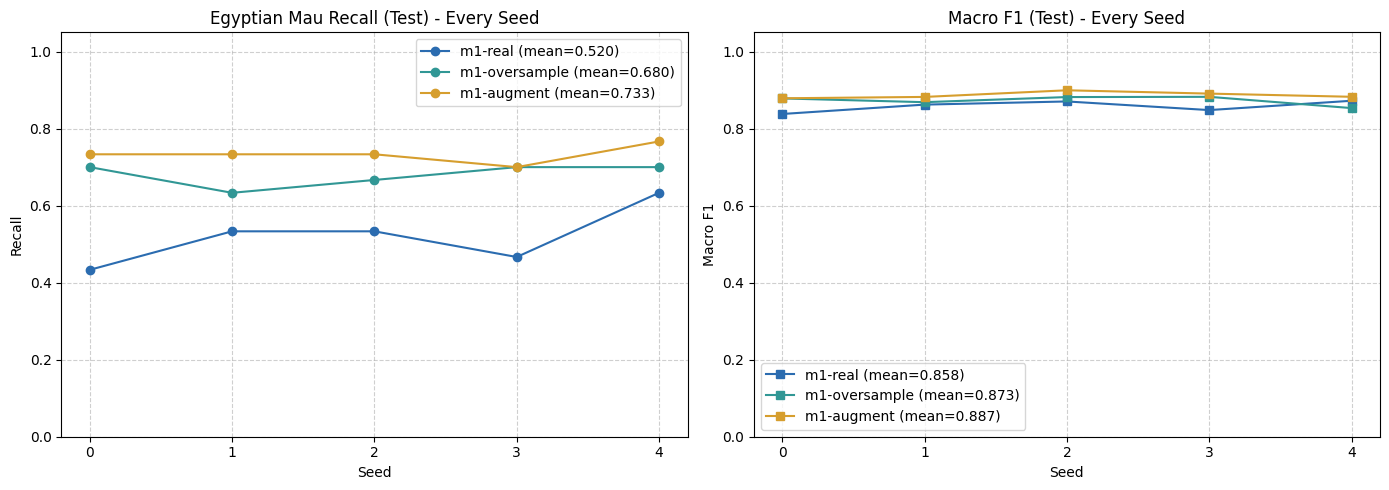

In [30]:
# Evaluate baselines on the test photos
!synth-test --run m1-real
!synth-test --run m1-oversample
!synth-test --run m1-augment

compare_runs(["m1-real", "m1-oversample", "m1-augment"], split="test");
tested_runs = ["m1-real", "m1-oversample", "m1-augment"]
format_seed_table(tested_runs, split="test")
plot_seeds(tested_runs, split="test", output_filename="m1_test_comparison.png")


## Meeting 2 — Text-to-Image Generation
Synthesize pools of Egyptian Mau images with Stable Diffusion 1.5 (or SDXL-Turbo), view the contact sheets, and train classifiers on the synthetic data.

In [ ]:
# Define your prompt
PROMPT = "a clear close-up portrait of an Egyptian Mau cat with spotted coat and green eyes, highly detailed photo"

# Generate base pool
!synth-generate --name m2-base --prompt "{PROMPT}"

# View contact sheet inline
show_contact_sheet("m2-base")


In [ ]:
# Train classifier with m2-base pool
!synth-train --name m2-base --method synthetic --pool m2-base

# Example parameter variation: Guidance scale
!synth-generate --name m2-guidance-3 --prompt "{PROMPT}" --guidance 3.0
!synth-train --name m2-guidance-3 --method synthetic --pool m2-guidance-3 --tag guidance=3.0

compare_runs(["m1-real", "m2-base", "m2-guidance-3"], split="val");


## Meeting 3 — Generation from Training Photos
Condition generation on the 15 real Egyptian Mau training photos:
- `--mode img2img`: `--strength` controls noise replacement.
- `--mode ip-adapter`: `--ip-adapter-scale` steers generation using image features.

In [ ]:
# img2img (example strength 0.5)
!synth-generate --name m3-strength-0.5 --mode img2img --strength 0.5 --prompt "{PROMPT}"
!synth-train --name m3-strength-0.5 --method synthetic --pool m3-strength-0.5 --tag mode=img2img --tag strength=0.5
show_contact_sheet("m3-strength-0.5")

# IP-Adapter (example scale 0.5)
!synth-generate --name m3-ip-0.5 --mode ip-adapter --ip-adapter-scale 0.5 --prompt "{PROMPT}"
!synth-train --name m3-ip-0.5 --method synthetic --pool m3-ip-0.5 --tag mode=ip-adapter --tag scale=0.5
show_contact_sheet("m3-ip-0.5")

compare_runs(["m1-real", "m3-strength-0.5", "m3-ip-0.5"], split="val");


## Meeting 4 — Editing Training Photos
- `--mode inpaint`: Keeps the cat and generates new backgrounds.
- `--mode outpaint`: Centers the cat and paints the expanded surroundings (`--outpaint-scale` 1.25 to 2.0).

In [ ]:
# Inpainting with background scenes
!synth-generate --name m4-backgrounds --mode inpaint \
    --prompt "an egyptian mau cat on a sunny wooden deck in a green garden" \
    --prompt "an egyptian mau cat sitting on a colorful oriental rug in a living room"
!synth-train --name m4-backgrounds --method synthetic --pool m4-backgrounds
show_contact_sheet("m4-backgrounds")

# Outpainting
!synth-generate --name m4-outpaint-1.5 --mode outpaint --outpaint-scale 1.5 --prompt "{PROMPT}"
!synth-train --name m4-outpaint-1.5 --method synthetic --pool m4-outpaint-1.5 --tag scale=1.5
show_contact_sheet("m4-outpaint-1.5")

compare_runs(["m1-real", "m4-backgrounds", "m4-outpaint-1.5"], split="val");


## Meeting 5 — Final Comparison & Evidence Generation
Collect the test results of your chosen runs from Meetings 1–4, generate summary plots, and save them in `evidence/`.

In [ ]:
# List of selected candidate runs from each meeting
SELECTED_RUNS = ["m1-real", "m1-oversample", "m1-augment"]  # Add your chosen m2, m3, m4 run names here

# Ensure test evaluation is run for all selected candidates
for run_name in SELECTED_RUNS:
    test_file = Path("runs") / run_name / "test-results.json"
    if not test_file.exists():
        print(f"Evaluating {run_name} on test photos...")
        !synth-test --run {run_name}

# Summary comparison
final_summary = compare_runs(SELECTED_RUNS, split="test")

# Generate comparison bar chart and save to evidence/
Path("evidence").mkdir(exist_ok=True)
plot_data = []
for r in SELECTED_RUNS:
    df = load_run_results(r, split="test")
    if not df.empty:
        plot_data.append({
            "Run": r,
            "Recall": df["egyptian_mau_recall"].mean(),
            "F1": df["macro_f1"].mean()
        })

if plot_data:
    pdf = pd.DataFrame(plot_data)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.bar(pdf["Run"], pdf["Recall"], color="#3182ce")
    ax1.set_title("Egyptian Mau Test Recall")
    ax1.set_ylim(0, 1.0)
    ax1.tick_params(axis='x', rotation=30)

    ax2.bar(pdf["Run"], pdf["F1"], color="#38a169")
    ax2.set_title("Macro F1 Test Score")
    ax2.set_ylim(0, 1.0)
    ax2.tick_params(axis='x', rotation=30)

    plt.tight_layout()
    evidence_plot = Path("evidence") / "meeting5_test_comparison.png"
    plt.savefig(evidence_plot, dpi=150)
    plt.show()
    print(f"Plot saved to: {evidence_plot}")


## 5. Save & Sync Your Work
Remember that Colab's default disk is erased when your session ends.
Save your work using either **Git Push to GitHub** or **One-Click Download**.

In [35]:
# Option 1: Commit and push back to GitHub from Colab
import getpass

GIT_USER = "AleksyPrawilow"
GIT_EMAIL = "a5.pravilov@gmail.com"  # update with your email

!git config user.name "{GIT_USER}"
!git config user.email "{GIT_EMAIL}"

# Prompt for token (or set GITHUB_TOKEN in Colab Secrets)
try:
    from google.colab import userdata
    gh_token = userdata.get('GITHUB_TOKEN')
except Exception:
    gh_token = None

if not gh_token:
    gh_token = getpass.getpass("Enter GitHub Personal Access Token (leave empty to skip): ")

if gh_token:
    !git remote set-url origin https://{gh_token}@github.com/AleksyPrawilow/synthetic-data.git
    !git status
    # Track results, manifests, evidence, and experiment log
    !git add EXPERIMENTS.md evidence/ runs/*/results.json runs/*/test-results.json #pools/*/manifest.jsonl pools/*/pool.json pools/*/contact-sheet.jpg
    !git commit -m "Colab run: update experiments and results" || echo "No changes to commit."
    !git push origin main
    print("✅ Successfully pushed to GitHub!")
else:
    print("Skipped git push.")


Enter GitHub Personal Access Token (leave empty to skip): ··········
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	evidence/m1_test_comparison.png
	evidence/m1_validation_comparison.png
	runs/m1-augment-strong/
	runs/m1-augment/
	runs/m1-oversample/
	runs/m1-real/

nothing added to commit but untracked files present (use "git add" to track)
[main b76c429] Colab run: update experiments and results
 9 files changed, 651 insertions(+)
 create mode 100644 evidence/m1_test_comparison.png
 create mode 100644 evidence/m1_validation_comparison.png
 create mode 100644 runs/m1-augment-strong/results.json
 create mode 100644 runs/m1-augment/results.json
 create mode 100644 runs/m1-augment/test-results.json
 create mode 100644 runs/m1-oversample/results.json
 create mode 100644 runs/m1-oversample/test-results.json
 create mode 100644 runs/m1-real/results.json
 create mode 100644 runs/m1-real/test-res

In [33]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	evidence/m1_test_comparison.png
	evidence/m1_validation_comparison.png
	runs/m1-augment-strong/
	runs/m1-augment/
	runs/m1-oversample/
	runs/m1-real/

nothing added to commit but untracked files present (use "git add" to track)


In [ ]:
# Option 2: Download results archive to your local computer
from google.colab import files

ZIP_FILE = "synthetic_data_results.zip"
# Exclude heavy model weights and full image directories (only keep contact sheets & manifests)
!zip -r -q {ZIP_FILE} evidence/ EXPERIMENTS.md runs/ pools/ \
    -x "runs/*/seed-*/model.pt" \
    -x "pools/*/images/*" \
    -x "*.tmp.png"

files.download(ZIP_FILE)
print(f"✅ Downloaded {ZIP_FILE} with all results, sheets, and evidence.")
